# 02 — El hospital: qué variables tenemos y qué mide cada una

**Fecha:** 2026-09-22 · **Corregido el 2026-09-29** · **Datos:** 433.620 triages, 2020-01-01 a
2026-09-21

> **Corrección del 2026-09-29.** Los 433.620 triages llegaban a un **22-sep-2026 parcial**, no
> al 21 → este cuaderno corta ahora en el **2026-09-20** y excluye la caída de registro del
> 21-mar-2024 (cuaderno 01, sección 0), igual que los cuadernos 01, 06 y 07. Con ese corte son
> **433.258** (salida de la celda de carga).

Este cuaderno cuenta el camino entero: lo que se creyó al escribirlo, y **lo que se supo
después**. Una afirmación que resultó falsa no se borra: queda visible con un recuadro
«Corrección del 2026-09-29» debajo.

---

## Qué contesta este cuaderno

El 01 miró **cuánta** gente viene y **cuándo**. Este mira **qué sabemos de cada consulta** y,
sobre todo, **qué mide realmente cada variable** — que no siempre es lo que su nombre sugiere.

Sin factores externos todavía. Primero hay que saber con qué cartas se juega.

## La distinción que organiza todo el cuaderno

No todas las columnas miden lo mismo, y confundirlas es el error más caro que se puede
cometer aquí:

| | Qué mide | Variables |
|---|---|---|
| **La población** | Cuánta gente enferma y de qué | conteo, edad, hora de llegada |
| **La institución** | Qué decide el hospital con esa gente | nivel de triage, estancia |

> **El conteo y la edad son un termómetro de Manizales. El nivel de triage y la estancia son
> un termómetro del hospital.** Los dos sirven, pero contestan preguntas distintas, y una
> variable del segundo grupo no se puede leer como si fuera del primero.

> **Corrección del 2026-09-29.** Faltaba una **tercera familia: la red**, quién paga la
> atención. Es la entidad administradora (`GEENENTADM`), y resultó ser la que más mueve el
> conteo total (sección 5). Tampoco es un termómetro de Manizales: el conteo puede caer sin
> que enferme menos gente, si una EPS deja de mandar a sus afiliados.
>
> | | Qué mide | Variables |
> |---|---|---|
> | **La red** | Quién paga y a dónde puede ir el paciente | entidad administradora (EPS, SOAT, ARL…) |

Esta distinción no estaba clara al empezar y costó una interpretación equivocada, que se
corrige en la sección 3.

## Premisas

- El desenlace del proyecto es el **conteo total** de triages (`CLAUDE.md`). Todo lo demás son
  variables que ayudan a entenderlo.
- **Todos los registros se tratan como verídicos** (sección 3).
- En los **subconjuntos** (una banda de edad, una EPS) un día sin filas sí es cero; en el total
  es una caída del registro (cuaderno 01, sección 0).

## De dónde salen los datos

Agregados sin dato personal; este cuaderno no se conecta a SQL Server. La única lectura de
base es el conteo de notas de `salidas/triage_vista.duckdb` (copia de solo lectura) en la
sección 1.

| Archivo | Qué es | Fuente original | Cómo se regenera |
|---|---|---|---|
| `salidas/triage_nivel.parquet` | día × hora × nivel de urgencia | `DIM_TRIAGE.HCNCLAURGTR` → `DIM_HCNCLAURGTR` (base del SES) | `python -m extraccion --series` |
| `salidas/triage_edad.parquet` | día × banda de edad (0-4, 5-14, 15-44, 45-64, 65+) | `DIM_TRIAGE.HCTEDAD`, solo en bandas | `python -m extraccion --series` |
| `salidas/triage_horario.parquet` | día × hora | `DIM_TRIAGE.HCTFECTRI` | sin script; coincide con `triage_nivel` sumado (cuaderno 01) |
| `salidas/triage_entidad.parquet` | día × hora × entidad administradora | `DIM_TRIAGE.GEENENTADM` → `DIM_ENTIDAD` | `python -m extraccion --entidad`; grupos con `extraccion.entidades.clasificar` |
| `calendarios/vigilancia_sivigila.csv.gz` | IRA semanal de Manizales (evento 995) | microdatos SIVIGILA, INS | `calendarios/vigilancia/sivigila.py` |
| `calendarios/seguridad_mindefensa.csv.gz` | lesiones de tránsito por día en Manizales | Policía / MinDefensa, datos.gov.co | `calendarios/seguridad/mindefensa.py` |
| `calendarios/clima_unificado.csv.gz` | clima diario de Manizales | IDEAM, METAR La Nubia, Open-Meteo, NASA POWER | `python calendarios/clima/clima_unificado.py` |
| `salidas/triage_vista.duckdb` | notas ya procesadas por el NLP | `nota_triage` (copia de lectura) | la refresca `python -m NLP.procesar` |

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from clustering.visualizaciones import datos, figuras
from extraccion.entidades import clasificar

AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "font.size": 10, "legend.frameon": False})

FIN = "2026-09-20"                         # el 21 y el 22 estan incompletos
CAIDOS = [pd.Timestamp("2024-03-21")]      # caida del registro (cuaderno 01, seccion 0)
def recorte(t):
    t = t.copy(); t["dia"] = pd.to_datetime(t["dia"])
    return t[(t["dia"] <= FIN) & ~t["dia"].isin(CAIDOS)]

nivel = recorte(pd.read_parquet(RAIZ / "salidas" / "triage_nivel.parquet"))
edad  = recorte(pd.read_parquet(RAIZ / "salidas" / "triage_edad.parquet"))
total = recorte(datos.marco(datos.total()))
entidad_completa = clasificar(pd.read_parquet(RAIZ / "salidas" / "triage_entidad.parquet"))
entidad = recorte(entidad_completa)

MES = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
print(f"nivel  : {len(nivel):,} filas dia x hora x nivel, {nivel['n'].sum():,} triages")
print(f"edad   : {len(edad):,} filas dia x banda, {edad['n'].sum():,} triages")
print(f"entidad: {entidad['n'].sum():,} triages hasta {FIN} "
      f"({entidad_completa['n'].sum():,} en el archivo, que llega a {entidad_completa['dia'].max():%Y-%m-%d})")

nivel  : 177,720 filas dia x hora x nivel, 433,258 triages
edad   : 12,324 filas dia x banda, 433,258 triages
entidad: 433,258 triages hasta 2026-09-20 (434,726 en el archivo, que llega a 2026-09-28)


---
# 1. El inventario: qué hay y desde cuándo

Medido el 2026-09-22 con `python -m extraccion --cobertura`.

| Variable | Qué es | Cobertura | Desde | ¿Sirve? |
|---|---|---|---|---|
| `HCTFECTRI` | Fecha y hora | **100 %** | 2020 | Sí, es el eje |
| `HCNCLAURGTR` | Nivel de triage | **100 %** | 2020 | Sí, **con reservas** (§3) |
| `HCTEDAD` | Edad | **100 %** | 2020 | Sí, en bandas (§2) |
| `HCCFECSAL` | Hora de salida → estancia | 91,1 % | 2020 | Solo régimen 2 |
| `HCTMOTCON` | Motivo, texto libre | 82,8 % / 76,2 % | **2025** | Pendiente del NLP |
| `GENDIAGNO1` | Diagnóstico CIE-10 | **0,6 %** | — | **No. Está vacío** |

> **Corrección del 2026-09-29.** Al inventario le faltaba una fila, añadida el 28-09:
>
> | Variable | Qué es | Cobertura | Desde | ¿Sirve? |
> |---|---|---|---|---|
> | `GEENENTADM` → `DIM_ENTIDAD` | Entidad administradora: la EPS, la aseguradora SOAT, la ARL… | 100 % en 2020-2024, 99 % en 2025-2026 | 2020 | **Sí**: es la red (§5) |
>
> La cobertura es la medida al extraerla (`docs/CONTEXTO.md`, «Cambio de método»); la
> sección 5 cuenta aquí lo que queda sin entidad.

## Dos cosas que hay que saber antes de seguir

**`GENDIAGNO1` casi fue el atajo del proyecto.** Apunta a `DIM_DIAGNOSTICO`, que tiene 12.427
filas con códigos de 10 caracteres: es CIE-10. Si estuviera poblada, habría una clasificación
clínica estructurada de cada triage desde 2020 y sobraría buena parte de la cadena de NLP.
**No lo está**: 0,6 % global, y cero en 2022, 2025 y 2026. Queda escrito para no volver a
buscarlo.

**La única variable con el motivo clínico es texto libre y empieza en 2025.** Eso deja una
asimetría que manda sobre el plan entero:

- Para **cuánta** gente viene y **de qué edad**: seis años y medio.
- Para **de qué se queja**: veinte meses, y hay que procesarlos con un modelo local.

In [2]:
# Cuantas notas tiene hoy procesadas el NLP. Solo un conteo, sobre la copia de lectura.
try:
    import duckdb
    con = duckdb.connect(str(RAIZ / "salidas" / "triage_vista.duckdb"), read_only=True)
    n_notas, desde, hasta = con.execute(
        "select count(*), min(fecha_triage), max(fecha_triage) from nota_triage").fetchone()
    con.close()
    print(f"notas procesadas por el NLP: {n_notas:,}, del {desde:%Y-%m-%d} al {hasta:%Y-%m-%d}")
except Exception as e:
    n_notas = None
    print("no se pudo leer la copia de la base:", type(e).__name__)

notas procesadas por el NLP: 3,087, del 2025-01-08 al 2025-01-24


> **Corrección del 2026-09-29.** «Pendiente del NLP» sigue siendo cierto, pero la etapa
> cambió: el 28-09 el propietario **apartó el NLP** para trabajar las variables externas
> (`docs/CONTEXTO.md`, «Se aparta el NLP…»). Lo procesado se quedó en **3.087 notas**, las
> del 8 al 24 de enero de 2025 (salida de la celda): unas dos semanas y media de veinte meses,
> alrededor del 3 % de las ~95 mil notas con texto que cuenta `CLAUDE.md`.

---
# 2. Quién viene: la edad

Es la variable menos mirada y la que más señal tiene. Está al 100 % desde 2020 y no depende
de ningún modelo.

In [3]:
comp = edad.groupby("banda")["n"].sum()
comp = 100 * comp / comp.sum()
orden = ["0-4", "5-14", "15-44", "45-64", "65-+"]
print("COMPOSICION POR EDAD (6,7 anios)")
for b in orden:
    print(f"  {b:<8}{comp[b]:5.1f}%  " + "#" * int(comp[b]))

edad["anio"] = edad["dia"].dt.year
por_anio = edad.pivot_table(index="anio", columns="banda", values="n", aggfunc="sum").fillna(0)
cuota = 100 * por_anio.div(por_anio.sum(axis=1), axis=0)
print("\nCUOTA POR ANIO (%)")
print(cuota[orden].round(1).to_string())

dias_anio = edad.groupby("anio")["dia"].nunique()
print("\nEN ABSOLUTO: TRIAGES POR DIA DE CADA BANDA")
print(por_anio[orden].div(dias_anio, axis=0).round(1).to_string())

COMPOSICION POR EDAD (6,7 anios)
  0-4       3.1%  ###
  5-14      4.4%  ####
  15-44    54.4%  ######################################################
  45-64    18.5%  ##################
  65-+     19.5%  ###################

CUOTA POR ANIO (%)
banda  0-4  5-14  15-44  45-64  65-+
anio                                
2020   1.9   3.0   55.1   19.8  20.2
2021   2.4   3.0   57.9   18.7  17.9
2022   3.2   4.5   56.5   17.9  17.8
2023   2.7   4.2   55.7   18.4  18.9
2024   3.0   4.5   53.8   18.9  19.5
2025   3.9   5.6   51.0   18.3  20.9
2026   4.0   5.1   51.0   18.0  21.8

EN ABSOLUTO: TRIAGES POR DIA DE CADA BANDA
banda  0-4  5-14  15-44  45-64  65-+
anio                                
2020   2.0   3.2   58.3   20.9  21.4
2021   3.6   4.6   86.5   27.9  26.7
2022   6.1   8.6  107.2   33.9  33.8
2023   5.2   8.2  107.2   35.5  36.3
2024   6.8  10.3  122.1   42.8  44.3
2025   7.9  11.3  101.9   36.6  41.7
2026   6.9   8.9   88.1   31.1  37.6


## Lectura

**El 54,4 % de las consultas son de personas entre 15 y 44 años.** Población en edad
laboral. Los menores de 15 son apenas el 7,5 %.

Eso es información directa sobre el mecanismo que el proyecto quiere medir. Un servicio
donde una de cada dos consultas es de alguien en edad de trabajar encaja con la hipótesis de
partida — la persona que necesita el soporte del día — mucho mejor que un servicio
pediátrico o geriátrico.

> **Corrección del 2026-09-29.** «La hipótesis de partida» (gripa → consulta por la
> incapacidad) era **un ejemplo del tipo de razonamiento**, no la hipótesis del proyecto
> (aclaración del propietario del 28-09 en `CLAUDE.md`). El dato sigue valiendo como
> descripción: la mitad de la demanda es población laboral.

**Y la composición se está moviendo, de forma consistente:**

| Banda | 2021 | 2026 | |
|---|---|---|---|
| 0-4 | 2,4 % | **4,0 %** | ↑ |
| 5-14 | 3,0 % | **5,1 %** | ↑ |
| 15-44 | 57,9 % | **51,0 %** | ↓ |
| 65+ | 17,9 % | **21,8 %** | ↑ |

**Los extremos de edad ganan peso y el centro lo pierde.** Es coherente con lo que se
encontró en el cuaderno 01: si la población adulta de baja complejidad se está desviando a
otro sitio, lo que queda pesa más hacia niños y mayores. Las dos observaciones se explican
con el mismo cambio.

> **Corrección del 2026-09-29.** «Se explican con el mismo cambio» era una conclusión; queda
> como **pregunta abierta** con un sospechoso más. En absoluto (última tabla de la salida),
> de 2024 a 2026 los 15-44 pasan de 122,1 a 88,1 triages por día (−28 %), los 65+ de 44,3 a
> 37,6 (−15 %) y los 0-4 de 6,8 a 6,9: **la cuota de los extremos sube porque los adultos caen
> más, no porque vengan más niños**. En esos años el cambio grande de la red es **la caída de
> Nueva EPS** (sección 5 y cuaderno 01, sección 4.2). Si los afiliados que Nueva EPS dejó de
> mandar eran sobre todo adultos, eso solo ya movería la composición. **No hay cruce edad ×
> entidad en los datos**, así que no se puede separar; haría falta un agregado nuevo día ×
> banda × grupo de entidad.

### Límites
Las bandas son anchas: 15-44 mezcla estudiantes, trabajadores y embarazadas (el 12,5 %
obstétrico del cuaderno 01 cae casi entero ahí).

## 2.1 La estacionalidad por edad — el hallazgo del cuaderno

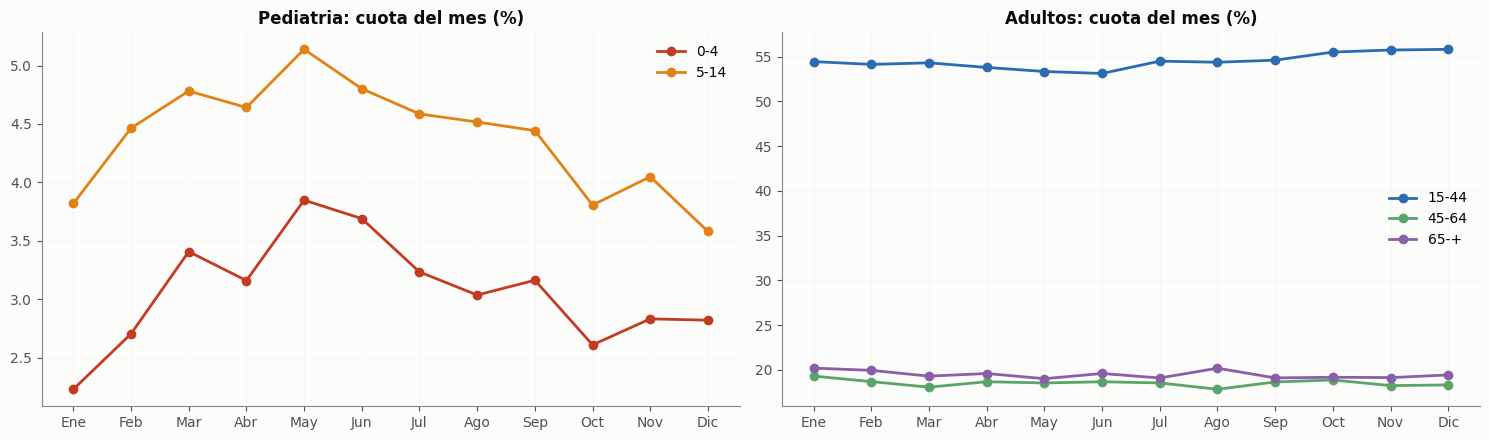

AMPLITUD ESTACIONAL DE CADA BANDA (max/min - 1)
  0-4      max May ( 3.85%)   min Ene ( 2.23%)   amplitud  72.5%
  5-14     max May ( 5.14%)   min Dic ( 3.58%)   amplitud  43.5%
  15-44    max Dic (55.82%)   min Jun (53.12%)   amplitud   5.1%
  45-64    max Ene (19.29%)   min Ago (17.82%)   amplitud   8.3%
  65-+     max Ene (20.18%)   min May (19.00%)   amplitud   6.2%

cuota de 0-4 y 5-14 por mes (%):
mes     Ene   Feb   Mar   Abr   May   Jun   Jul   Ago   Sep   Oct   Nov   Dic
banda                                                                        
0-4    2.23  2.70  3.41  3.16  3.85  3.69  3.23  3.04  3.16  2.61  2.83  2.82
5-14   3.82  4.46  4.78  4.64  5.14  4.80  4.59  4.52  4.44  3.81  4.05  3.58


In [4]:
edad["mes"] = edad["dia"].dt.month
pm = edad.pivot_table(index="mes", columns="banda", values="n", aggfunc="sum").fillna(0)
cm = 100 * pm.div(pm.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for b, c in zip(["0-4", "5-14"], ["#c23b22", "#e08214"]):
    ax1.plot(range(1, 13), cm[b], marker="o", lw=2, label=b, color=c)
ax1.set_title("Pediatria: cuota del mes (%)", fontsize=12)
for b, c in zip(["15-44", "45-64", "65-+"], ["#2b6cb0", "#5aa469", "#8b5fa8"]):
    ax2.plot(range(1, 13), cm[b], marker="o", lw=2, label=b, color=c)
ax2.set_title("Adultos: cuota del mes (%)", fontsize=12)
for ax in (ax1, ax2):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MES); ax.legend(frameon=False)
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("AMPLITUD ESTACIONAL DE CADA BANDA (max/min - 1)")
for b in orden:
    s = cm[b]
    print(f"  {b:<8} max {MES[s.idxmax()-1]} ({s.max():5.2f}%)   min {MES[s.idxmin()-1]} ({s.min():5.2f}%)"
          f"   amplitud {100*(s.max()/s.min()-1):5.1f}%")
print("\ncuota de 0-4 y 5-14 por mes (%):")
print(cm[["0-4", "5-14"]].rename(index=lambda m: MES[m-1]).T.round(2).to_string())

## Lectura — esto es lo más importante que ha salido hasta ahora

| Banda | Amplitud estacional | Pico | Valle |
|---|---|---|---|
| **0-4** | **72,5 %** | **Mayo** | Enero |
| **5-14** | **43,5 %** | **Mayo** | Diciembre |
| 45-64 | 8,3 % | Enero | Agosto |
| 65+ | 6,2 % | Enero | Mayo |
| 15-44 | 5,1 % | Diciembre | Junio |

> **Las bandas pediátricas tienen entre 7 y 14 veces más amplitud estacional que las
> adultas.** Y no oscilan en cualquier dirección: suben juntas de marzo a junio y caen juntas
> de octubre a enero.

> **Corrección del 2026-09-29.** Se conserva como hallazgo, pero **no es «lo más importante»
> del proyecto ni su objetivo**: lo respiratorio y lo pediátrico eran un **ejemplo**, y el
> desenlace es el triage total (`docs/CONTEXTO.md`, «Corrección del propietario: el ejemplo de
> la gripa no es el objetivo»). Lo que se supo después y lo refuerza como hallazgo:
> - **El cuaderno 07** encontró que tras un paso de **seco a lluvioso**, los niños de 0-4 años
>   suben **+22,0 ± 17,8 % a los 7-13 días**, y el efecto se apaga a la cuarta semana (13
>   episodios; es 1 de 36 comparaciones y falta confirmarlo fuera de muestra).
> - **La IRA 0-4 de Manizales en el SIVIGILA** se mueve con el triage 0-4 del SES: la celda
>   de la sección 2.2 da **r = 0,703** en 312 semanas, la misma cifra de
>   `calendarios/docs/VIGILANCIA.md`. El SES casi no reporta IRA al SIVIGILA, así que no es una correlación
>   mecánica.
> - Las amplitudes de la tabla se rehicieron con el corte común y no cambian (salida de la
>   celda).

> **Corrección del 2026-09-29 (clima corregido).** El resultado del 07 citado arriba se midió
> con un pluviómetro que reportaba cero de octubre de 2025 a julio de 2026 (cuaderno 03,
> sección 3.1). Con el clima corregido: **+22,0 ± 17,8 % a los 7-13 días (13 episodios) →
> +13,4 ± 15,0 % a los 7-13 días y +10,0 ± 16,4 % a los 14-20 días (17 episodios)**. Conserva la
> forma (sube a la primera y segunda semana, se apaga a la cuarta), pero **ya no se distingue de
> cero**, así que deja de reforzar el hallazgo. La correlación con la IRA 0-4 del SIVIGILA y las
> amplitudes no dependen de la lluvia y no cambian.

**Esa es la firma clásica de una temporada respiratoria.** Los niños son el indicador
adelantado de la circulación viral, y en Colombia el primer pico de infección respiratoria
aguda está documentado entre marzo y mayo.

### Y encaja con la lluvia, pero solo a medias

La precipitación corregida de Manizales (ver nota de la sección 6) es **bimodal**: picos en
**abril** y en **octubre-noviembre**, valles en enero y julio.

- **El primer pico de lluvia (abril) precede en un mes al pico pediátrico (mayo).** Un rezago
  de esa magnitud es exactamente lo que predice el mecanismo: incubación más decisión de
  consultar.
- **El segundo pico de lluvia (octubre-noviembre) NO tiene pico pediátrico detrás.** Ahí la
  cuota de 0-4 está en su mínimo.

> **Corrección del 2026-09-29.** El clima unificado se reescribió el 23-09
> (`calendarios/docs/CLIMA.md`) y la lluvia de referencia es ahora el pluviómetro → con la
> serie actual (sección 6) la primera temporada de lluvias va de **marzo a junio, con el mes
> más lluvioso en marzo**, no en abril, y los valles son enero-febrero y septiembre, no enero
> y julio. El pico pediátrico de mayo cae **dentro** de la temporada, no un mes después de su
> pico; el «rezago de un mes» ya no se lee en la climatología. Lo que sigue en pie: el
> segundo pico de lluvia (octubre-noviembre) no tiene pico pediátrico detrás. Y la mínima de
> 0-4 no está en octubre sino en **enero** (salida de la celda).

> **Corrección del 2026-09-29 (clima corregido).** El pluviómetro reportaba cero de octubre de
> 2025 a julio de 2026 y ya se corrigió (cuaderno 03, sección 3.1). Con la serie corregida
> (sección 6): **marzo sigue siendo el mes más lluvioso** (4,33 → 5,67 mm/día) y la temporada
> sigue siendo marzo-junio (junio 3,85 → 5,31). Cambian los valles: **enero deja de ser valle**
> (1,95 → 3,11 mm/día) y febrero sube (1,49 → 2,48); el valle claro queda en **septiembre**
> (1,81, sin cambio), con diciembre y febrero detrás. Lo que se decía del pico pediátrico no
> cambia: mayo cae dentro de la temporada, y octubre-noviembre (4,51 y 3,07) sigue sin pico
> pediátrico detrás.

### Qué significa que solo encaje a medias

**Que la lluvia sola no lo explica, y está bien que así sea.** Si encajaran los dos picos, la
explicación más simple sería estacionalidad compartida y no un mecanismo. Que encaje uno y no
el otro obliga a buscar qué distingue abril de octubre — y ahí entran el calendario escolar,
la circulación viral de cada año y la temperatura.

**Es una hipótesis falsable y con los datos para probarla ya en el repositorio.** No requiere
una sola nota de texto.

### Límites

- Esto es el **promedio de siete años**. Un promedio puede esconder que cada año el pico cae
  en un mes distinto. Hay que mirarlo año a año antes de darlo por bueno.
- **La cuota no es el conteo.** Que suba la cuota de 0-4 puede ser porque vienen más niños o
  porque vienen menos adultos. Hay que verlo también en absoluto.
- El calendario escolar colombiano y la temporada de lluvias se solapan. **Están confundidos**
  y separarlos requiere un diseño, no una figura.

## 2.2 Contraste con la ciudad: la IRA 0-4 del SIVIGILA

*Sección añadida el 2026-09-29*, para que la cifra citada en el recuadro anterior salga de
este cuaderno. Método de `calendarios/docs/VIGILANCIA.md`: triage 0-4 del SES sumado por semana
epidemiológica (domingo a sábado, solo semanas completas; un día sin filas de 0-4 cuenta como
cero) contra las consultas por IRA de 0-4 años en Manizales (evento 995), 2020-2025.

semanas: 312   r en nivel = 0.703   r normalizando por la media de cada anio = 0.808


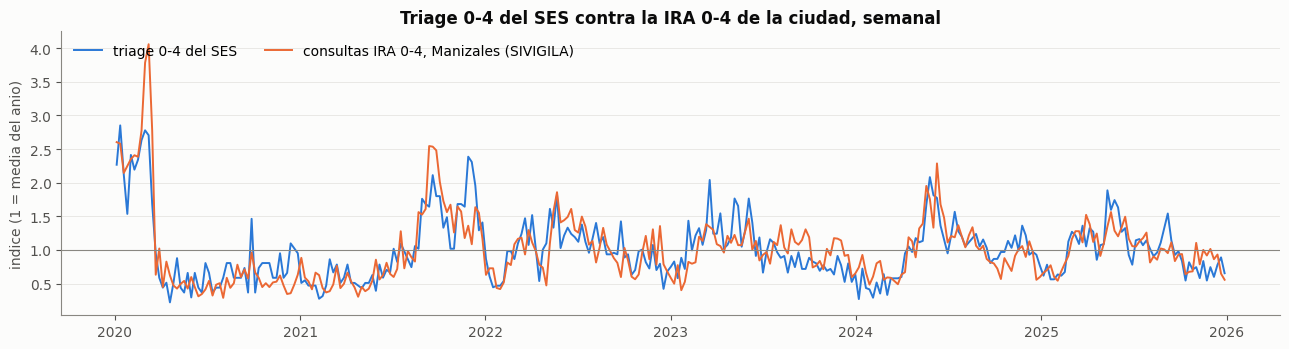

In [5]:
v = pd.read_csv(RAIZ / "calendarios" / "vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = (v[(v.evento == 995) & (v.ambito == "manizales") & (v.variable == "consultas_ira_0_4")]
         .groupby("fecha_inicio_semana")["valor"].sum())
d04 = (edad[edad.banda == "0-4"].set_index("dia")["n"]
         .reindex(pd.date_range("2020-01-01", FIN)).fillna(0))
d04[CAIDOS] = np.nan
w = d04.resample("W-SAT").agg(["sum", "count"]); w.index = w.index - pd.Timedelta(days=6)
w = w[w["count"] == 7]["sum"]
J = pd.concat([w.rename("triage 0-4"), ira.rename("IRA 0-4 Manizales")], axis=1).dropna().loc["2020":"2025"]
r = J.corr().iloc[0, 1]
Jn = J / J.groupby(J.index.year).transform("mean")
print(f"semanas: {len(J)}   r en nivel = {r:.3f}   r normalizando por la media de cada anio = {Jn.corr().iloc[0,1]:.3f}")

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(Jn.index, Jn["triage 0-4"], color=AZUL, lw=1.4, label="triage 0-4 del SES")
ax.plot(Jn.index, Jn["IRA 0-4 Manizales"], color=NARANJA, lw=1.4, label="consultas IRA 0-4, Manizales (SIVIGILA)")
ax.axhline(1, color=MUDO, lw=.8); ax.set_ylabel("indice (1 = media del anio)"); ax.grid(axis="y")
ax.set_title("Triage 0-4 del SES contra la IRA 0-4 de la ciudad, semanal"); ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

## Lectura

**El triage pediátrico del SES sube y baja con la IRA pediátrica de la ciudad**: r = 0,703 en
nivel en 312 semanas, y **0,808** al quitar el nivel de cada año (salida de la celda), así que
no es una tendencia compartida sino la forma de la temporada. Reproduce exactamente el 0,703
de `VIGILANCIA.md`.

### Límites
- Correlación de dos series con la misma estacionalidad: dice que la temporada es la misma, no
  que una cause la otra. Semana a semana la correlación es mucho menor (0,18-0,22 en
  `VIGILANCIA.md`).
- El cuaderno 07 buscó el efecto de las **subidas** de la IRA de la ciudad sobre el triage
  total del SES y no encontró nada. Esto vale para el 0-4, que es el 3 % del total.

---
# 3. El nivel de triage — y una corrección de interpretación

El nivel está al 100 % desde 2020. Pero **mide algo distinto de lo que parece**, y en la
sesión anterior se interpretó mal.

In [6]:
resumen = (nivel.groupby(["nivel", "nivel_nombre"])["n"].sum()
           .sort_values(ascending=False).reset_index())
resumen["cuota"] = 100 * resumen["n"] / resumen["n"].sum()
print(f"{'nivel':<8}{'descripcion':<44}{'n':>10}{'cuota':>8}")
for _, r in resumen.head(8).iterrows():
    print(f"{r.nivel:<8}{str(r.nivel_nombre)[:42]:<44}{r.n:>10,}{r.cuota:>7.1f}%")
iv_v = resumen.loc[resumen.nivel.isin(["IV", "V"]), "cuota"].sum()
print(f"\nIV + V: {iv_v:.1f} %")

nivel   descripcion                                          n   cuota


IV      DIFERIDA/NO URGENTE                            169,651   39.2%
IIIU    URGENCIA                                       106,550   24.6%
V       CONSULTA EXTERNA                                52,986   12.2%
III-G   URGENCIA OBSTETRICA DIFERIDA O MENOR            47,285   10.9%
III     DIFERIDA                                        41,693    9.6%
II      URGENCIA MEDICA                                  6,477    1.5%
II-G    URGENCIA MEDICA OBSTETRICA                       6,296    1.5%
I       EMERGENCIA                                       1,460    0.3%

IV + V: 51.4 %


## La corrección

Al ver que el 51,4 % de los triages son «no urgente» o «consulta externa», la lectura
inmediata fue que el hospital recibe consultas que no lo ameritan. **Esa lectura es
incorrecta**, y la corrigió el propietario con un argumento que los datos no pueden dar:

> *«el hospital no está en la capacidad de recibir a cualquier persona e ingresarlo y
> tratarlo, directamente es inviable […] yo he venido con dolores muy fuertes pensando que me
> voy a morir y lo que me dicen es que no es tan grave y que me vaya para la EPS con cita
> prioritaria. Lo más seguro es que me marcan como no urgente o diferido y pasan al
> siguiente.»*

**El nivel de triage no califica la legitimidad de la consulta. Califica qué va a hacer el
hospital con ella.** Son dos cosas distintas:

| | |
|---|---|
| Lo que el nivel **no** dice | Si el paciente tenía razón en venir |
| Lo que el nivel **sí** dice | Si este servicio lo va a atender aquí o lo remite |

Un «no urgente» es una persona que llegó con un síntoma real y a la que se le resolvió por
otra vía. **Como dato de demanda poblacional es tan válido como un «urgente».**

### Las tres consecuencias

1. **Todos los registros se tratan como verídicos.** No hay forma de separar quién exageró, y
   tampoco hace falta: el conteo mide que alguien sintió la necesidad de consultar, que es
   justamente lo que el proyecto quiere predecir.
2. **El nivel es una variable de la institución, no de la población.** Depende del criterio
   del personal y de la capacidad del servicio en ese momento. Sirve para caracterizar al
   hospital y para entender qué prioriza — no para medir la gravedad de lo que pasa en la
   ciudad.
3. **El umbral puede moverse con la presión del servicio.** Y eso lo vuelve interesante por
   otro motivo: **un nivel que se endurece puede ser en sí mismo un indicador de saturación.**

## 3.1 La deriva del criterio

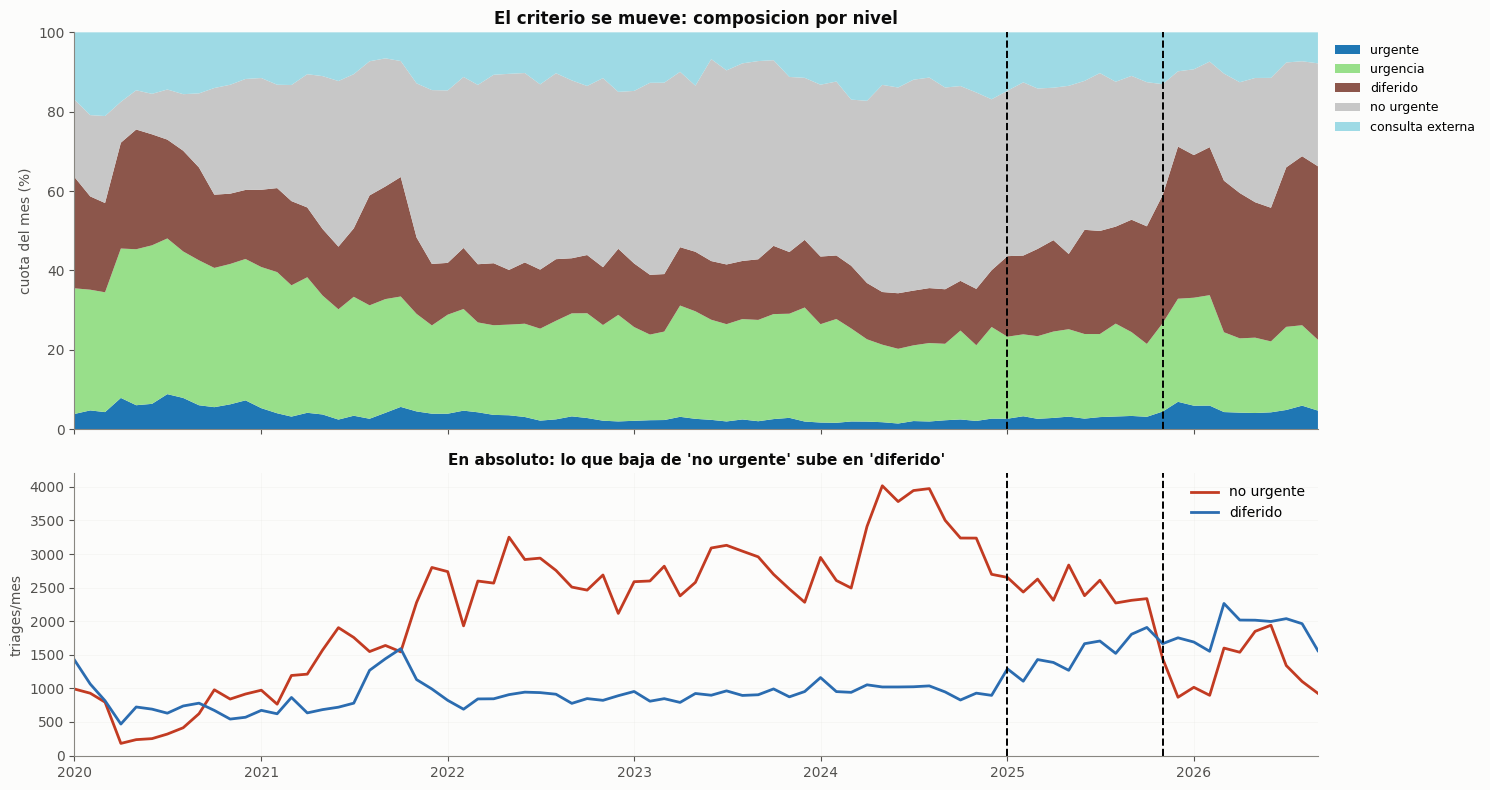

In [7]:
GRUPO = {"I": "urgente", "II": "urgente", "I-G": "urgente", "II-G": "urgente",
         "IIIU": "urgencia", "III": "diferido", "III-G": "diferido",
         "IV": "no urgente", "IV-G": "no urgente",
         "V": "consulta externa", "V-G": "consulta externa"}
nivel["grupo"] = nivel["nivel"].map(GRUPO).fillna("otro")
orden_g = ["urgente", "urgencia", "diferido", "no urgente", "consulta externa"]

mens = nivel.assign(ym=nivel["dia"].dt.to_period("M")).pivot_table(
    index="ym", columns="grupo", values="n", aggfunc="sum").fillna(0)[orden_g]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                               gridspec_kw={"height_ratios": [1.4, 1]})
x = mens.index.to_timestamp()
cuota_m = 100 * mens.div(mens.sum(axis=1), axis=0)
ax1.stackplot(x, cuota_m.to_numpy().T, labels=cuota_m.columns,
              colors=plt.get_cmap("tab20")(np.linspace(0, 1, mens.shape[1])))
ax1.set_ylim(0, 100); ax1.set_ylabel("cuota del mes (%)")
ax1.set_title("El criterio se mueve: composicion por nivel", fontsize=12)
ax1.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=9, frameon=False)

for c, col in zip(["no urgente", "diferido"], ["#c23b22", "#2b6cb0"]):
    ax2.plot(x, mens[c], lw=2, label=c, color=col)
ax2.set_ylabel("triages/mes"); ax2.legend(frameon=False); ax2.grid(alpha=.3)
ax2.set_title("En absoluto: lo que baja de 'no urgente' sube en 'diferido'", fontsize=11)
for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp("2025-01-01"), color="black", lw=1.4, ls="--")
    ax.axvline(pd.Timestamp("2025-11-01"), color="black", lw=1.4, ls="--")
ax1.set_xlim(x.min(), x.max())
plt.tight_layout(); plt.show()

## Lectura

**El panel de abajo es la prueba.** «No urgente» cae y «diferido» sube, en absoluto y casi en
espejo. No es que dejen de venir: es que **los mismos pacientes reciben otra etiqueta**.

La deriva arranca en **enero de 2025** y se acelera en **noviembre-diciembre de 2025**.
Hay dos explicaciones posibles y no son excluyentes:

1. **Cambió el criterio** — la misma persona que en 2024 era IV, en 2026 es III.
2. **Cambió quién llega** — los de menor complejidad se desviaron a otro sitio.

**La segunda sola no basta**: si solo fuera desvío, «diferido» no subiría en términos
absolutos, y sube casi el doble. Hay reetiquetado.

> **Corrección del 2026-09-29.** La segunda explicación tiene ahora nombre para el tramo de
> **noviembre de 2025 en adelante**: es cuando **Nueva EPS se desploma en el SES**. Desde ese mes
> la cuota de «no urgente» sube y baja con la cuota de Nueva EPS (r = +0,63 en 11 meses;
> cuaderno 01, sección 4.2). De enero a octubre de 2025, en cambio, la cuota de Nueva EPS no
> cae y «no urgente» sí: ese tramo es cambio de criterio. Las dos cosas son reales y
> distintas; ninguna cambia el **conteo** por sí misma más allá de la gente que dejó de venir.

> **Consecuencia operativa: un «triage IV» de 2024 y uno de 2026 no son la misma cosa.** El
> nivel sirve dentro de un periodo, no entre periodos. Para comparar años hay que usar el
> conteo total y la edad, que no dependen del criterio de nadie.

### Límites
Sin cruce nivel × entidad no se sabe qué nivel tenían los afiliados de Nueva EPS que dejaron
de venir. Las figuras de esta sección conservan los colores de la versión original.

---
# 4. Qué queda en pie — el mapa de variables

In [8]:
filas = [
    ("conteo total",      "poblacion",   "100%", "2020", "si",  "el desenlace"),
    ("edad en bandas",    "poblacion",   "100%", "2020", "si",  "senal estacional fuerte"),
    ("hora de llegada",   "poblacion",   "100%", "2020", "si",  "13,9x de oscilacion"),
    ("nivel de triage",   "institucion", "100%", "2020", "con reservas", "deriva desde 2025"),
    ("estancia",          "institucion", "91%",  "2020", "con reservas", "solo regimen 2"),
    ("motivo (texto)",    "poblacion",   "80%",  "2025", "pendiente", "1,5% procesado"),
    ("diagnostico CIE-10","poblacion",   "0,6%", "-",    "no",  "esta vacio"),
]
print(f"{'variable':<20}{'mide':<13}{'cobert':<8}{'desde':<7}{'usable':<15}{'nota'}")
for f in filas:
    print(f"{f[0]:<20}{f[1]:<13}{f[2]:<8}{f[3]:<7}{f[4]:<15}{f[5]}")

variable            mide         cobert  desde  usable         nota
conteo total        poblacion    100%    2020   si             el desenlace
edad en bandas      poblacion    100%    2020   si             senal estacional fuerte
hora de llegada     poblacion    100%    2020   si             13,9x de oscilacion
nivel de triage     institucion  100%    2020   con reservas   deriva desde 2025
estancia            institucion  91%     2020   con reservas   solo regimen 2
motivo (texto)      poblacion    80%     2025   pendiente      1,5% procesado
diagnostico CIE-10  poblacion    0,6%    -      no             esta vacio


## Lo que esto deja para la fase de predicción

**Tres variables limpias, al 100 % y con 6,7 años**: el conteo, la edad y la hora. Con eso
solo ya se puede:

- Construir el control de calendario en serio (cuaderno 03).

> **Corrección del 2026-09-29.** El «cuaderno 03» de control de calendario **no existe**. El
> control se construyó dentro de los cuadernos 05, 06 y 07 (día de la semana, festivos,
> vacaciones y nivel de cada año). El número 03 queda para un cuaderno nuevo, **«las fuentes
> externas»**: de dónde sale cada una, su cobertura y sus escalones (`docs/CONTEXTO.md`, «Los
> cuadernos cuentan la historia completa»).

- Probar la hipótesis respiratoria por la vía pediátrica, **sin una sola nota de texto**.

> **Corrección del 2026-09-29.** Lo respiratorio era un **ejemplo**, no la hipótesis del
> proyecto; la vía pediátrica queda como auditoría de coherencia de las fuentes, no como
> camino principal.

- Medir contra seis años y medio en vez de veinte meses.

**Dos variables con reserva**: el nivel y la estancia. Usables dentro de su régimen, no entre
regímenes. Y las dos son de la institución: dicen cómo responde el hospital, no cuánta gente
enferma.

**Una pendiente**: el motivo. Es el desenlace específico y sigue siendo el que más valor
añade — pero llega en 2025, justo cuando empieza la deriva, y va por el 1,5 %.

> **Corrección del 2026-09-29.** El motivo va por **3.087 notas** (≈3 %) y está **en pausa**
> desde el 28-09 (sección 1). Y al mapa le falta la variable de la red, que es la que más
> mueve el conteo: el mapa actualizado está al final de la sección 5.

---
# 5. La variable que faltaba: la entidad administradora

*Sección añadida el 2026-09-29.* `DIM_TRIAGE.GEENENTADM` apunta a `DIM_ENTIDAD`: quién paga la
atención. Se extrajo el 28-09 con `python -m extraccion --entidad` (día × hora × entidad, solo
conteos; el nombre es de una organización, no de una persona) y las ~330 entidades se agrupan
por nombre con `extraccion.entidades.clasificar`. Es la **tercera familia**:

| | Qué mide | Variables |
|---|---|---|
| La población | Cuánta gente enferma y de qué | conteo, edad, hora |
| La institución | Qué decide el hospital con ella | nivel, estancia |
| **La red** | **Quién paga y a dónde puede ir el paciente** | **entidad administradora** |

Y trae dos **huellas de mecanismo sin leer el motivo**: el **SOAT** es el seguro de accidentes
de tránsito, y la **ARL**, el de accidentes laborales.

REPARTO DE LOS TRIAGES POR ENTIDAD (434,726 en el archivo, 2020-01-01 a 2026-09-28)
                          todo el archivo (%)  hasta 2026-09-20 (%)
grupo                                                              
Nueva EPS                                58.2                  58.3
EPS Sura                                 22.2                  22.2
Otras EPS                                 6.1                   6.1
SOAT (transito)                           4.0                   4.0
Regimen especial                          2.5                   2.5
Prepagada                                 1.8                   1.8
Particulares                              1.3                   1.3
Ente territorial                          1.3                   1.3
ARL (laboral)                             1.0                   1.0
IPS remitente                             0.6                   0.6
Sin entidad                               0.3                   0.3
ADRES / FOSYGA                  

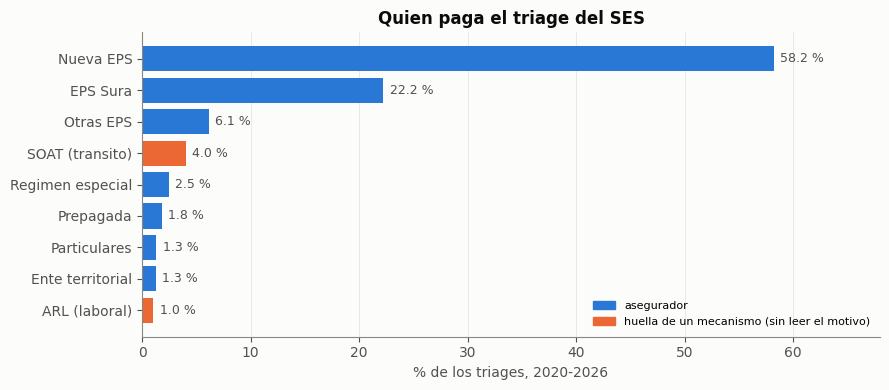


TRIAGES POR DIA, MEDIA DEL ANIO


      Nueva EPS  EPS Sura  Otras EPS  SOAT (transito)  ARL (laboral)  Particulares
dia                                                                               
2020       64.8       8.6       11.6              5.6            1.6           3.0
2021       86.1      16.8       19.7              7.8            1.9           4.7
2022      125.3      28.5       12.8              8.1            1.8           2.2
2023      122.9      41.1        8.8              7.0            1.7           1.4
2024      125.6      69.6        7.6              7.8            2.0           1.8
2025      115.8      53.9        6.6              6.0            1.7           1.3
2026       72.2      62.0        8.0              7.7            2.3           1.2

sin entidad por anio (%): {2020: 0.0, 2021: 0.0, 2022: 0.0, 2023: 0.0, 2024: 0.0, 2025: 0.99, 2026: 1.16}


In [9]:
NOMBRE = {"nueva_eps": "Nueva EPS", "sura_eps": "EPS Sura", "otra_eps": "Otras EPS",
          "soat_aseguradora": "SOAT (transito)", "regimen_especial": "Regimen especial",
          "prepagada": "Prepagada", "particular": "Particulares", "arl": "ARL (laboral)",
          "ente_territorial": "Ente territorial", "ips_remitente": "IPS remitente",
          "sin_entidad": "Sin entidad", "adres_fosyga": "ADRES / FOSYGA", "otro": "Otro",
          "nueva_eps_complementario": "Nueva EPS complementario"}
rep = pd.DataFrame({
    "todo el archivo (%)": 100 * entidad_completa.groupby("grupo")["n"].sum() / entidad_completa["n"].sum(),
    f"hasta {FIN} (%)": 100 * entidad.groupby("grupo")["n"].sum() / entidad["n"].sum()}
).sort_values("todo el archivo (%)", ascending=False)
rep.index = rep.index.map(NOMBRE)
print(f"REPARTO DE LOS TRIAGES POR ENTIDAD ({entidad_completa['n'].sum():,} en el archivo, "
      f"{entidad_completa['dia'].min():%Y-%m-%d} a {entidad_completa['dia'].max():%Y-%m-%d})")
print(rep.round(1).to_string())

top = rep["todo el archivo (%)"].iloc[:9][::-1]
huella = ["SOAT (transito)", "ARL (laboral)"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top.index, top.values, color=[NARANJA if k in huella else AZUL for k in top.index])
for y, v_ in enumerate(top.values):
    ax.text(v_ + .6, y, f"{v_:.1f} %", va="center", fontsize=9, color=TINTA2)
from matplotlib.patches import Patch
ax.set_xlabel("% de los triages, 2020-2026"); ax.set_xlim(0, 68); ax.grid(axis="x"); ax.set_axisbelow(True)
ax.set_title("Quien paga el triage del SES")
ax.legend(handles=[Patch(color=AZUL, label="asegurador"),
                   Patch(color=NARANJA, label="huella de un mecanismo (sin leer el motivo)")],
          loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

g = entidad.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").fillna(0)
por_dia = g.groupby(g.index.year).mean()[["nueva_eps", "sura_eps", "otra_eps", "soat_aseguradora", "arl", "particular"]]
por_dia.columns = [NOMBRE[c] for c in por_dia.columns]
print("\nTRIAGES POR DIA, MEDIA DEL ANIO")
print(por_dia.round(1).to_string())
sin = entidad.assign(anio=entidad["dia"].dt.year, s=np.where(entidad["grupo"] == "sin_entidad", entidad["n"], 0)).groupby("anio")[["s", "n"]].sum()
print("\nsin entidad por anio (%):", (100 * sin["s"] / sin["n"]).round(2).to_dict())

## Lectura

**El SES es, sobre todo, un hospital de Nueva EPS.** Reparto de los 434.726 triages del
archivo (salida de la celda):

| Grupo | % |
|---|---|
| **Nueva EPS** | **58,2** |
| EPS Sura | 22,2 |
| Otras EPS | 6,1 |
| **SOAT (accidente de tránsito)** | **4,0** |
| Régimen especial | 2,5 |
| Prepagada | 1,8 |
| Particulares | 1,3 |
| **ARL (accidente laboral)** | **1,0** |

Con el corte común del 20-sep Nueva EPS da 58,3 %; el resto no cambia.

- **Es la variable que más mueve el conteo total.** Nueva EPS pasa de 115,8 triages por día
  en 2025 a **72,2** en 2026 (tabla de la salida), mientras Sura sube de 53,9 a 62,0. Casi toda
  la caída del total desde 2024 es suya (cuaderno 01, sección 4.2). Contexto del propietario:
  la Supersalud intervino Nueva EPS por corrupción el 3-abr-2024; quedó al borde de la quiebra
  y sin poder pagar tratamientos, y sus afiliados dejaron de venir.
- **No es población ni institución.** Que Nueva EPS caiga no dice que Manizales enferme menos
  ni que el SES decida distinto: dice que una parte de la demanda **tiene otro camino** o
  ninguno. Por eso es una familia aparte.
- **El SOAT y la ARL son huellas.** Un triage pagado por SOAT es un accidente de tránsito, y
  uno pagado por ARL, un accidente laboral, sin haber leído una sola nota. El cuaderno 07 las
  usó así: en la Feria el SOAT sube +37 % frente a +12 % de otros regresos de vacaciones.

casos por dia 2022-03 a 2026-08: transito en la ciudad 3.1, SOAT en el SES 7.2
r semanal en conteo: -0.005   (235 semanas)


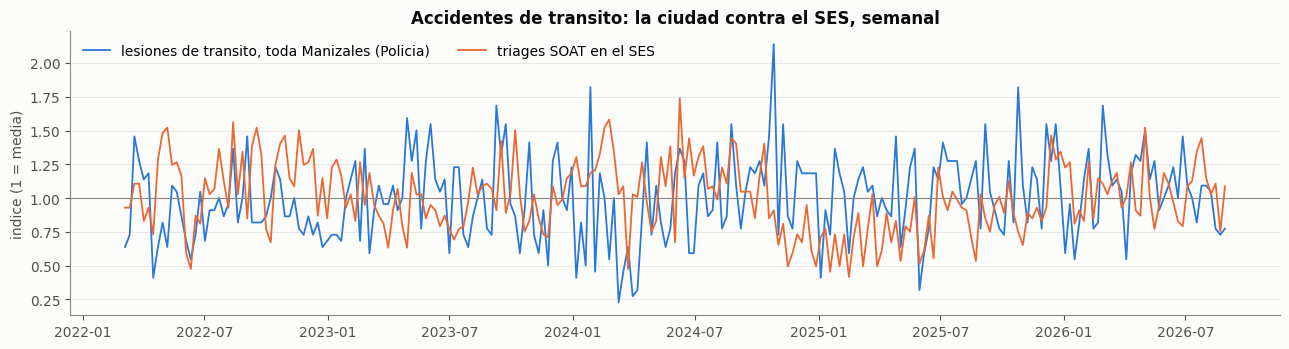

In [10]:
seg = pd.read_csv(RAIZ / "calendarios" / "seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha")
soat = g["soat_aseguradora"].reindex(pd.date_range("2020-01-01", FIN)).fillna(0)
A = pd.DataFrame({"ciudad": seg["lesiones_transito"], "SOAT en el SES": soat}).loc["2022-03-01":"2026-08-28"]
Aw = A.resample("W-SAT").sum()
print(f"casos por dia 2022-03 a 2026-08: transito en la ciudad {A.ciudad.mean():.1f}, SOAT en el SES {A['SOAT en el SES'].mean():.1f}")
print(f"r semanal en conteo: {Aw.ciudad.corr(Aw['SOAT en el SES']):+.3f}   ({len(Aw)} semanas)")

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(Aw.index, Aw.ciudad / Aw.ciudad.mean(), color=AZUL, lw=1.3, label="lesiones de transito, toda Manizales (Policia)")
ax.plot(Aw.index, Aw["SOAT en el SES"] / Aw["SOAT en el SES"].mean(), color=NARANJA, lw=1.3, label="triages SOAT en el SES")
ax.axhline(1, color=MUDO, lw=.8); ax.set_ylabel("indice (1 = media)"); ax.grid(axis="y")
ax.set_title("Accidentes de transito: la ciudad contra el SES, semanal"); ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

## Lectura

**El SOAT del SES no se mueve con los accidentes de la ciudad.** En conteo semanal la
correlación sale prácticamente cero (salida de la celda); el cuaderno 07, quitando calendario
y año, da **r = +0,01** por día y por semana. El SES recibe unos 7 triages SOAT por día y la
Policía registra unos 3 lesionados por día en toda Manizales: no son la misma población.

Encaja con lo que describe el propietario: los accidentados de la ciudad van sobre todo a otras
clínicas, y al SES llegan remitidos de otros municipios, accidentes que no se denuncian o
consultas días después. **Solo en la Feria suben los dos** (cuaderno 07, sección 3.1).
Consecuencia: el tránsito de la ciudad **no** entra como predictor del triage del SES; la
Feria sí.

### Límites
- La clasificación de entidades es un **borrador** que revisa el propietario
  (`salidas/entidades_clasificadas.csv`). Los grupos pequeños («otro», 0,2 %; «ente
  territorial», 1,3 %) pueden esconder aseguradoras SOAT o ARL mal clasificadas.
- Lo que queda **sin entidad** por año está en la salida anterior; es poco, pero crece en
  2025-2026, como decía la medición de cobertura.
- La residencia del paciente **no** se usa, por decisión del propietario.
- La serie de la Policía solo cuenta lo denunciado y tiene escalones de registro
  (`calendarios/docs/FUENTES_EXTERNAS.md`).

In [11]:
# Mapa de variables actualizado el 2026-09-29
motivo = f"{n_notas:,} notas, en pausa" if n_notas else "en pausa"
filas_nuevas = [
    ("conteo total",       "poblacion",   "100%", "2020", "si",           "el desenlace"),
    ("edad en bandas",     "poblacion",   "100%", "2020", "si",           "estacionalidad pediatrica"),
    ("hora de llegada",    "poblacion",   "100%", "2020", "si",           "13,9x de oscilacion"),
    ("entidad admin.",     "red",         "99-100%", "2020", "si",        "Nueva EPS: el nivel del total"),
    ("nivel de triage",    "institucion", "100%", "2020", "con reservas", "deriva desde 2025"),
    ("estancia",           "institucion", "91%",  "2020", "con reservas", "solo regimen 2"),
    ("motivo (texto)",     "poblacion",   "80%",  "2025", "pendiente",    motivo),
    ("diagnostico CIE-10", "poblacion",   "0,6%", "-",    "no",           "esta vacio"),
]
print(f"{'variable':<20}{'mide':<13}{'cobert':<9}{'desde':<7}{'usable':<15}{'nota'}")
for f in filas_nuevas:
    print(f"{f[0]:<20}{f[1]:<13}{f[2]:<9}{f[3]:<7}{f[4]:<15}{f[5]}")

variable            mide         cobert   desde  usable         nota
conteo total        poblacion    100%     2020   si             el desenlace
edad en bandas      poblacion    100%     2020   si             estacionalidad pediatrica
hora de llegada     poblacion    100%     2020   si             13,9x de oscilacion
entidad admin.      red          99-100%  2020   si             Nueva EPS: el nivel del total
nivel de triage     institucion  100%     2020   con reservas   deriva desde 2025
estancia            institucion  91%      2020   con reservas   solo regimen 2
motivo (texto)      poblacion    80%      2025   pendiente      3,087 notas, en pausa
diagnostico CIE-10  poblacion    0,6%     -      no             esta vacio


---
# 6. Nota: el clima de Manizales, y un error en los datos que ya existen

*(Era la sección 5 en la versión del 22-09.)*

Este cuaderno no usa clima. Pero al verificar el contexto geográfico apareció algo que hay
que dejar dicho antes de que alguien construya encima.

## Lo que dicen los datos sobre el clima de aquí

Medido sobre `calendarios/clima_unificado.csv`, 2.432 días:

| | |
|---|---|
| Temperatura media | 16,5 °C (sd 0,64) |
| Temperatura máxima media | 21,2 °C |
| **Días con máxima > 26 °C, en 6,7 años** | **0** |
| Días con máxima > 25 °C | 5 (0,21 %) |
| Humedad media | 87,2 % |

**Aquí no hace calor. Nunca.** En 2.432 días la máxima no llegó a 26 °C ni una sola vez.
Manizales está a ~2.150 m en la Cordillera Central, junto al Nevado del Ruiz, y eso se ve en
los datos: el rango térmico anual completo cabe en cuatro grados.

**Consecuencia para las hipótesis:** el mecanismo vectorial (dengue, chikunguña) necesita
calor sostenido y aquí no lo hay. La vía local queda descartada; lo que queda son pacientes
remitidos de municipios bajos de Caldas, y las epidemias que sí encajan con este clima:
respiratorias, virales, fúngicas. Que es la hipótesis original del proyecto.

> **Corrección del 2026-09-29.** «La hipótesis original del proyecto» era un ejemplo; el
> desenlace es el triage total. Y las cifras de la tabla son de la versión del clima anterior
> a la reescritura del 23-09; la celda siguiente las rehace con el archivo actual.

dias: 2,432 (2020-01-01 a 2026-08-28)
temperatura media  16.6 C (sd 0.76)
maxima media       21.0 C
dias con maxima > 26 C: 0   > 25 C: 4 (0.16 %)
humedad media      86.9 %

lluvia 2020-2025: 1292 mm/anio de media  {2020: 1074, 2021: 828, 2022: 1729, 2023: 1390, 2024: 1424, 2025: 1310}
mm/dia por mes: {'Ene': 3.11, 'Feb': 2.48, 'Mar': 5.67, 'Abr': 4.26, 'May': 3.8, 'Jun': 5.31, 'Jul': 3.16, 'Ago': 2.58, 'Sep': 1.81, 'Oct': 4.51, 'Nov': 3.07, 'Dic': 2.42}
solo dias con pluviometro: {'Ene': 3.33, 'Feb': 2.21, 'Mar': 6.6, 'Abr': 5.17, 'May': 3.52, 'Jun': 5.57, 'Jul': 3.15, 'Ago': 2.77, 'Sep': 2.03, 'Oct': 5.4, 'Nov': 2.92, 'Dic': 2.58}
dias con pluviometro: 34.7 %   'llovio' (>= 1 mm): 64.0 %


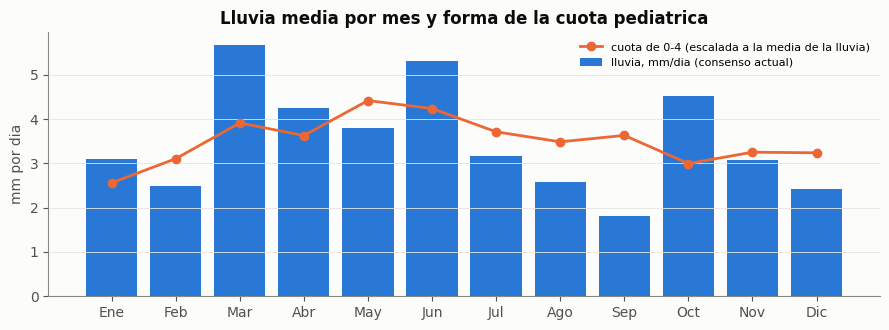

In [12]:
cl = pd.read_csv(RAIZ / "calendarios" / "clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
t = cl["temp_media_consenso"]; tx = cl["temp_max_consenso"]
print(f"dias: {len(cl):,} ({cl.index.min():%Y-%m-%d} a {cl.index.max():%Y-%m-%d})")
print(f"temperatura media  {t.mean():.1f} C (sd {t.std():.2f})")
print(f"maxima media       {tx.mean():.1f} C")
print(f"dias con maxima > 26 C: {(tx > 26).sum()}   > 25 C: {(tx > 25).sum()} ({100*(tx > 25).mean():.2f} %)")
print(f"humedad media      {cl['humedad_consenso'].mean():.1f} %")

p = cl["precip_consenso_mm"]
anual = p.loc["2020":"2025"].groupby(p.loc["2020":"2025"].index.year).sum()
print(f"\nlluvia 2020-2025: {anual.mean():.0f} mm/anio de media  {anual.round(0).astype(int).to_dict()}")
pm_ = p.groupby(p.index.month).mean()
print("mm/dia por mes:", {MES[m-1]: round(v_, 2) for m, v_ in pm_.items()})
con_est = p.where(cl["precip_con_estacion"] == 1)
print("solo dias con pluviometro:", {MES[m-1]: round(v_, 2) for m, v_ in con_est.groupby(con_est.index.month).mean().items()})
print(f"dias con pluviometro: {100*cl['precip_con_estacion'].mean():.1f} %   'llovio' (>= 1 mm): {100*cl['llovio'].mean():.1f} %")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(1, 13), pm_.values, color=AZUL, label="lluvia, mm/dia (consenso actual)")
c04 = cm["0-4"]
ax.plot(range(1, 13), c04 / c04.mean() * pm_.mean(), color=NARANJA, marker="o", lw=2,
        label="cuota de 0-4 (escalada a la media de la lluvia)")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MES); ax.set_ylabel("mm por dia"); ax.grid(axis="y")
ax.set_title("Lluvia media por mes y forma de la cuota pediatrica"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

## Lectura de la comprobación

> **Corrección del 2026-09-29.** Con el clima actual (salida de la celda): temperatura media
> **16,6 °C (sd 0,76)**, no 16,5 (sd 0,64); máxima media **21,0 °C**, no 21,2; días con máxima
> sobre 25 °C **4**, no 5; humedad **86,9 %**, no 87,2. **Días sobre 26 °C: sigue en 0.** La
> conclusión («aquí no hace calor») no cambia.

La figura pone la forma de la cuota de 0-4 sobre la lluvia solo para comparar la **forma**:
las dos series tienen unidades distintas y la naranja está reescalada. La cuota pediátrica
sube con la temporada de marzo-junio y no responde a la de octubre-noviembre.

### Límites
Solo el ~43 % de los días tiene pluviómetro; el resto usa NASA escalado, que acierta el mes
pero no el día (`calendarios/docs/CLIMA.md`). Para una climatología mensual basta.

> **Corrección del 2026-09-29 (clima corregido).** La celda se volvió a ejecutar con el clima
> corregido (`pluviometro_fallido`, cuaderno 03). La temperatura, la máxima, los días sobre 25 °C y
> la humedad **no cambian**: la corrección solo toca la lluvia. Lo que cambia:
> - días con pluviómetro: **42,9 → 34,7 %** (los 199 días en falla dejan de contar);
> - `llovio` (≥ 1 mm): **58,5 → 64,0 %** de los días;
> - lluvia media 2020-2025: **1.081 → 1.292 mm/año**;
> - mm/día de enero a julio y de octubre (los meses del calendario que tuvieron días en falla):
>   ene 1,95 → 3,11; feb 1,49 → 2,48; mar 4,33 → 5,67; abr 3,28 → 4,26; may 2,92 → 3,80; jun 3,85
>   → 5,31; jul 2,78 → 3,16; oct 3,34 → 4,51. Agosto, septiembre, noviembre y diciembre no se mueven.
>
> El «~43 %» del límite pasa a ser ~35 %.

## El error: `precip_consenso_mm` está inflado y con el ciclo invertido

| Fuente | mm/año | Pico | Valle |
|---|---|---|---|
| Estación IDEAM | 1.403 | Abr | Feb |
| NASA POWER | 1.904 | Abr | Jul |
| **Open-Meteo** | **16.555** | **Jul** | **Ene** |
| **Consenso actual** | **4.393** | **Jun** | Ene |

Manizales recibe unos **2.000 mm/año**. Open-Meteo reporta **16.555** — ocho veces más que la
realidad y más que el lugar más lluvioso del planeta. Y su ciclo anual está invertido
respecto a la climatología conocida.

**Por qué se cuela en el consenso:** `clima_unificado.py` toma la **mediana** de las tres
fuentes. Con tres, Open-Meteo queda fuera de la mediana y no hace daño. Pero **la estación
IDEAM solo cubre el 72,6 % de los días**, y en el 27,6 % restante la mediana de dos valores
es su promedio:

| Días con | Consenso resultante |
|---|---|
| 3 fuentes (72,2 %) | 6,55 mm/día ✔ |
| **2 fuentes (27,6 %)** | **26,40 mm/día** ✘ |

**La causa raíz está escrita en el propio script**, `clima_manizales.py` línea 68: *«era5_land
NO devuelve precipitation_sum → la precipitación se pide aparte al modelo era5»*. Ese modelo
tiene celdas de ~28 km; en la Cordillera Central una celda así promedia el valle del
Magdalena con la montaña.

## El arreglo, y lo que aparece al hacerlo

Quitando Open-Meteo de la mediana: **1.765 mm/año** — dentro del rango real — y el ciclo
anual se vuelve **bimodal**, como debe ser:

- Picos en **abril** (6,99 mm/día) y **octubre-noviembre** (5,43 / 5,70)
- Valles en **enero** (3,36) y **julio** (3,52)

**Y con esa serie corregida es con la que hay que releer la sección 2.1**: el pico pediátrico
de mayo va justo detrás del pico de lluvia de abril.

> **Todo lo que dependa de `precip_consenso_mm`, `precip_7d`, `precip_30d`, `llovio` o
> `lluvia_fuerte` está calculado sobre una variable rota.** Eso incluye las cifras de
> `patrones/` y la afirmación de que «llovió» es cierta el 98,8 % de los días — que es cierta
> del dato inflado, no del clima de Manizales.

> **Corrección del 2026-09-29.** El diagnóstico del error era correcto, pero **el arreglo que
> se propone aquí no es el que se hizo**. El 23-09 `clima_unificado.py` se reescribió entero
> por seis problemas, no uno (`calendarios/docs/CLIMA.md`): la referencia de la lluvia pasó a
> ser **el pluviómetro** y NASA solo rellena, escalado. Con el archivo actual (celda anterior)
> la lluvia media 2020-2025 es de **~1.080 mm/año**, no 1.765; la estación marca el mes más
> lluvioso en **marzo** y la temporada va de marzo a junio, con la segunda en octubre-noviembre
> y valles en enero-febrero y septiembre. Que el total quede por debajo de los ~2.000 mm
> municipales está documentado y no se sabe resolver; no afecta a nada que se mida en anomalías
> del propio mes. `llovio` es cierta el **58,5 %** de los días. La variable **ya no está rota**
> y los cuadernos 06 y 07 la usan.

> **Corrección del 2026-09-29 (clima corregido).** Estaba rota otra vez, en la dirección
> contraria: de octubre de 2025 a julio de 2026 el pluviómetro reportaba cero y el archivo lo
> tomaba como dato, fabricando sequías. Ya se corrigió (`pluviometro_fallido`, cuaderno 03). La
> lluvia media 2020-2025 pasa de **~1.080 a ~1.290 mm/año**, más cerca de los ~2.000 municipales
> pero todavía por debajo; `llovio`, de **58,5 a 64,0 %**. Marzo sigue siendo el mes más lluvioso
> y la temporada marzo-junio; el valle queda en **septiembre**, y enero deja de serlo.

---
# Conclusiones (del 2026-09-22, con sus correcciones)

## Lo que ahora se sabe del hospital

1. **El 54,4 % de las consultas son de personas de 15 a 44 años.** Población laboral, que es
   la que encaja con el mecanismo del soporte de incapacidad.

> **Corrección del 2026-09-29.** El mecanismo de la incapacidad era un ejemplo, no el
> objetivo. El dato de la población laboral sigue en pie.

2. **Los extremos de edad ganan peso**: 0-4 de 2,4 % a 4,0 %, 65+ de 17,9 % a 21,8 %.

> **Corrección del 2026-09-29.** Ganan peso porque los 15-44 caen más (−28 % por día de 2024 a
> 2026), no porque vengan más niños. Hay un sospechoso nuevo, la caída de Nueva EPS, y sin
> cruce edad × entidad queda como **pregunta abierta** (sección 2).

3. **Las bandas pediátricas tienen 7-14× más estacionalidad que las adultas**, con pico en
   mayo y valle en enero. Es la firma de una temporada respiratoria.

> **Corrección del 2026-09-29.** Se mantiene como hallazgo, pero como **ejemplo**, no como el
> objetivo. Lo refuerzan el cuaderno 07 (seco → lluvioso: 0-4 años +22 % a los 7-13 días, 13
> episodios) y la IRA 0-4 de la ciudad (r = 0,703; sección 2.2).

> **Corrección del 2026-09-29 (clima corregido).** Seco → lluvioso en 0-4 años: **+22 % (13
> episodios) → +13,4 ± 15,0 % a los 7-13 días (17 episodios)**, que ya no se distingue de cero.
> Queda como refuerzo solo la IRA 0-4 de la ciudad.

4. **El nivel de triage mide la decisión del hospital, no la gravedad del paciente.** Todos
   los registros son demanda real.
5. **El criterio del nivel derivó desde enero de 2025**, con reetiquetado demostrable.

> **Corrección del 2026-09-29.** Desde noviembre de 2025 una parte del cambio de la
> composición por nivel va junto con la caída de Nueva EPS (sección 3.1). La deriva de enero a
> octubre de 2025 sigue siendo de criterio.

6. **No hay diagnóstico CIE-10**: la columna existe y está vacía.
7. *(Añadido el 2026-09-29.)* **Hay una tercera familia de variables, la red**: la entidad
   administradora. Nueva EPS es el 58,2 % de los triages y su caída es la de todo el hospital.
   El SOAT y la ARL son huellas de accidentes sin leer el motivo, y el SOAT del SES no se mueve
   con los accidentes de la ciudad (sección 5).

## Lo que este cuaderno cambia en el plan

- **La vía pediátrica se adelanta.** Prueba la hipótesis respiratoria con 6,7 años y sin
  depender del NLP. Pasa a ser el camino principal, no el alternativo.

> **Corrección del 2026-09-29.** Revertido por el propietario el 28-09: la etapa es de
> **recolección e inventario de variables externas** y el desenlace es el total. Lo pediátrico
> queda como auditoría de coherencia de las fuentes.

- **Hay que arreglar la precipitación antes de tocar cualquier cruce con clima.**

> **Corrección del 2026-09-29.** Hecho el 23-09 (sección 6).

- **Las comparaciones entre años se hacen con conteo y edad**, nunca con nivel.

> **Corrección del 2026-09-29.** Y con el asegurador delante: el conteo entre años está
> dominado por el estado de Nueva EPS.

## Lo que queda abierto

- **¿La estacionalidad pediátrica se repite cada año, o el promedio la fabrica?** Hay que
  verla año a año. Es lo primero del próximo cuaderno.
- **¿Es la lluvia, el calendario escolar o la circulación viral?** Los tres se solapan en
  marzo-junio. Separarlos requiere diseño, no una figura más.
- **¿Qué pasó en enero y noviembre de 2025?** Sigue sin respuesta y sigue condicionando qué
  ventana de años es modelable.

> **Corrección del 2026-09-29.** **Noviembre de 2025 tiene respuesta**: Nueva EPS se desploma
> en el SES (cuaderno 01, sección 4.2; cuaderno 07, sección 5). **Enero de 2025** sigue abierto:
> la deriva del criterio empieza sin que cambie el asegurador. Sobre la repetición año a año,
> `calendarios/docs/VIGILANCIA.md` da la correlación con la IRA 0-4 por año (0,44 a 0,92).
- *(Añadido el 2026-09-29.)* **¿A quién dejó de atender el SES de Nueva EPS: qué edades y qué
  niveles?** Hace falta un agregado nuevo, día × banda × nivel × grupo de entidad, por
  `extraccion/` y con su `GROUP BY`.

---
# Lo que se supo después

- **[01 — La serie de triage](01_la_serie_de_triage.ipynb)** (corregido el 29-09). Un hueco de
  registro el 19-21 de marzo de 2024; la caída del 23,9 % no es artefacto de la reclasificación
  sino de **Nueva EPS**; la segunda joroba del día es a las 14-15 h.
- **[05 — Validación sin motivo](05_validacion_sin_motivo.py)** (28-09; script). Las variables
  externas no mejoraron el pronóstico semanal del **total**; las pediátricas sí respondían al
  clima (frío y humedad a 1-2 semanas). Fue la primera señal de que lo pediátrico es un
  subgrupo con su propio reloj.
- **[06 — Patrones exploratorios](06_patrones_exploratorios.ipynb)** (28-09). Fijó el SES en el
  SIVIGILA (`170010010301`) y comprobó que el hospital casi no reporta IRA, así que la
  correlación con la ciudad no es mecánica. Sus lecturas «no afecta» se matizaron en el 07.
- **[07 — Mecanismos](07_mecanismos.ipynb)** (28-09). La red (Nueva EPS −38 % en 2026), la Feria
  con su huella SOAT, el paso de seco a lluvioso en 0-4 años (+22 %) y el tránsito de la ciudad
  sin relación con el SOAT del SES (r = 0,01).
- **`docs/CONTEXTO.md`, 28-09:** «Corrección del propietario: el ejemplo de la gripa no es el
  objetivo» y «Dos capas: el nivel lo mueve la red, los picos los mueven otras cosas».

> **Corrección del 2026-09-29 (clima corregido).** El pluviómetro de La Nubia reportaba cero de
> octubre de 2025 a julio de 2026 y ya se corrigió (`pluviometro_fallido`, cuaderno 03). En el 07,
> seco → lluvioso en 0-4 años pasa de **+22 % (13 episodios)** a **+13,4 ± 15,0 % a los 7-13 días
> y +10,0 ± 16,4 % a los 14-20 días (17 episodios)**, y ya no se distingue de cero. La red, la
> Feria y el tránsito no dependen de la lluvia y no cambian. El 05 ya es un cuaderno
> (`05_validacion_sin_motivo.ipynb`) y se volvió a ejecutar con el clima corregido: su conclusión
> no cambia.

**Lo que sigue en pie de este cuaderno:** el nivel mide la decisión del hospital; todos los
registros son demanda real; el criterio derivó desde 2025; no hay CIE-10; la estacionalidad
pediátrica es fuerte; en Manizales no hace calor.